# RQ2 - Ridge meta-learner (stacking ablation)

This notebook studies the second stage of the Hybrid model. It reads the base-learner predictions (XGBoost, LightGBM, GRU) saved by the Hybrid notebook (`hybrid_base_predictions.csv`) and compares ways of combining them: the non-negative Ridge meta-learner used in the Hybrid, an unconstrained Ridge, non-negative least squares, the plain mean and the best single learner.

Protocol: run 1 fits the combiner on the Validation block (base learners trained on Train); run 2 fits it on out-of-fold predictions over Train+Val (base learners refitted on Train+Val). The Test block (2020-01-16 to the end of the data) is never used for fitting.

In [1]:
MODEL_TAG, MODEL_NAME = 'ridge_meta', 'Ridge meta-learner'

In [2]:
# ====================== SHARED CONFIG (identical in every RQ2/RQ3 notebook) ======================
import os, sys, glob, json, random, warnings, subprocess, time, hashlib, platform, base64, gzip, io
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.metrics import mean_absolute_error, mean_squared_error
pd.set_option('display.width', 250, 'display.max_columns', None, 'display.max_rows', 500)

FAST_MODE   = False        # True = smoke test only
SEED        = 42
SITES       = [1, 2]       # one hourly series (and one model) per site; site 19 is dropped (too sparse)
HORIZONS    = [1, 24]      # H=1 next hour, H=24 one day ahead (direct strategy)

# ---- Split requested by the author: Train -> 31/10/2019, Val -> 15/01/2020, Test = 16/01/2020 -> end of data ----
TRAIN_END   = '2019-10-31 23:00'
VAL_END     = '2020-01-15 23:00'
# Two training protocols:
#   run1 : fit on Train, early-stop / select on Val, evaluate on Test        (train - val - test)
#   run2 : refit on Train+Val with the settings chosen in run1, evaluate on Test   (train(train+val) - test)

MAX_LOOKBACK = 168         # longest history window (hours) any model may read
WARMUP_H     = 24 * 28     # first 4 weeks of each series are never targets (672 h of history needed by seasonal_mean_4w)
GAP_DAYS     = 7           # >= 7 consecutive hours-days with zero energy = data outage, not demand
POST_GAP_H   = 24 * 28     # after every outage the next 4 weeks are not targets (lags would read the artificial zeros)
MAPE_MIN     = 0.5         # kWh; MAPE/sMAPE only on hours with at least this load
N_BOOT       = 1000
BLOCK_H      = 24 * 7
if FAST_MODE: N_BOOT = 100
random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3,
                     'axes.spines.top': False, 'axes.spines.right': False})

# ---- The 16 common features (CFV) used by EVERY forecasting model ----
FEATS_COMMON = ['lag_H', 'lag_D', 'lag_168', 'roll_mean_24', 'roll_max_24', 'seasonal_mean_4w',
                'n_plugged_lagH', 'n_charging_lagH', 'n_arrivals_lagH', 'charging_share_lagH',
                'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'is_holiday']
assert len(FEATS_COMMON) == 16
FEATS_HASH = hashlib.md5('|'.join(FEATS_COMMON).encode()).hexdigest()[:10]
CAL = ['hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'is_holiday']
HIST_COLS = ['y_s', 'plug_s', 'chg_s', 'arr_s']          # 4 dynamic channels for recurrent nets

In [3]:
# ---------- Output folder + data file ----------
OUT_DIR = '/kaggle/working' if os.path.exists('/kaggle/working') else './outputs_' + MODEL_TAG
FIG_DIR = os.path.join(OUT_DIR, 'figures'); os.makedirs(FIG_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, f'{MODEL_TAG}_{name}.png'), dpi=140, bbox_inches='tight'); plt.show()
def resolve_data():
    pats = ['/kaggle/input/**/acn_data*.xlsx', '/kaggle/input/**/acn*.xlsx', './acn*.xlsx', '/mnt/user-data/uploads/**/acn*.xlsx']
    for p in pats:
        hits = sorted(glob.glob(p, recursive=True))
        if hits: return hits[0]
    raise FileNotFoundError('acn*.xlsx not found. Add the ACN dataset as notebook input.')
DATA_PATH = resolve_data()
print('Model:', MODEL_NAME, '| data:', DATA_PATH, '| python', sys.version.split()[0])

# ---------- Read + clean sessions ----------
try: raw = pd.read_excel(DATA_PATH, sheet_name='full_data')
except ValueError: raw = pd.read_excel(DATA_PATH)
for c in ['connectionTime', 'disconnectTime', 'doneChargingTime']: raw[c] = pd.to_datetime(raw[c])
sess = raw.drop_duplicates(['stationID', 'connectionTime']).copy()
sess['done'] = sess['doneChargingTime'].clip(upper=sess['disconnectTime'])
sess = sess[(sess.kWhDelivered > 0) & (sess.disconnectTime > sess.connectionTime)]
sess = sess[sess.siteID.isin(SITES)].reset_index(drop=True)
print(f'sessions after cleaning (sites {SITES}): {len(sess):,} / raw {len(raw):,}')

# ---------- Hourly load series per site ----------
def spread_energy(s):
    c = s.connectionTime.values.astype('datetime64[s]'); e = s.done.values.astype('datetime64[s]')
    e = np.maximum(e, c + np.timedelta64(60, 's'))
    c0 = c.astype('datetime64[h]'); e0 = (e - np.timedelta64(1, 's')).astype('datetime64[h]')
    n = ((e0 - c0) // np.timedelta64(1, 'h')).astype(int) + 1
    idx = np.repeat(np.arange(len(s)), n)
    k = np.arange(n.sum()) - np.repeat(np.cumsum(n) - n, n)
    hs = c0[idx] + k.astype('timedelta64[h]'); he = hs + np.timedelta64(1, 'h')
    ov = (np.minimum(e[idx], he) - np.maximum(c[idx], hs)) / np.timedelta64(1, 's')
    tot = ((e - c) / np.timedelta64(1, 's'))[idx]
    return pd.Series(s.kWhDelivered.values[idx] * ov / tot, index=pd.DatetimeIndex(hs)).groupby(level=0).sum()

def hourly_site(s):
    y = spread_energy(s)
    grid = pd.date_range(s.connectionTime.min().floor('h'), s.done.max().ceil('h'), freq='h', name='time')
    out = pd.DataFrame(index=grid); out['y'] = y.reindex(grid).fillna(0.0)
    ends = (grid + pd.Timedelta(hours=1)).values
    conn = np.sort(s.connectionTime.values); disc = np.sort(s.disconnectTime.values); done = np.sort(s.done.values)
    out['n_plugged_end']  = np.searchsorted(conn, ends, 'right') - np.searchsorted(disc, ends, 'right')
    out['n_charging_end'] = np.searchsorted(conn, ends, 'right') - np.searchsorted(done, ends, 'right')
    out['n_arrivals'] = pd.Series(1, index=s.connectionTime.dt.floor('h')).groupby(level=0).sum().reindex(grid).fillna(0).values
    return out

hol = USFederalHolidayCalendar().holidays('2018-01-01', '2021-12-31')
def add_calendar(Hs):
    ix = Hs.index
    Hs['hour_sin'] = np.sin(2*np.pi*ix.hour/24);     Hs['hour_cos'] = np.cos(2*np.pi*ix.hour/24)
    Hs['dow_sin']  = np.sin(2*np.pi*ix.dayofweek/7); Hs['dow_cos']  = np.cos(2*np.pi*ix.dayofweek/7)
    Hs['is_weekend'] = (ix.dayofweek >= 5).astype(float)
    Hs['is_holiday'] = ix.normalize().isin(hol).astype(float)     # US federal calendar, NOT the file's is_holiday column
    return Hs

T_END, V_END = pd.Timestamp(TRAIN_END), pd.Timestamp(VAL_END)
HOURLY, GAP_RUNS, SCALE, THR90, MASE_SCALE = {}, {}, {}, {}, {}
for sid in SITES:
    s = sess[sess.siteID == sid]
    Hs = hourly_site(s)
    assert abs(Hs.y.sum() - s.kWhDelivered.sum()) < 1e-3, 'kWh not conserved'
    inactive = (Hs.y == 0); grp = (inactive != inactive.shift()).cumsum()
    Hs['in_gap'] = inactive & (inactive.groupby(grp).transform('size') >= GAP_DAYS * 24)
    _g = (Hs.in_gap != Hs.in_gap.shift()).cumsum()
    GAP_RUNS[sid] = [(g.index.min(), g.index.max()) for _, g in Hs[Hs.in_gap].groupby(_g[Hs.in_gap])]
    post = np.zeros(len(Hs), bool)
    for a, b in GAP_RUNS[sid]:
        j = Hs.index.get_loc(b); post[j + 1: j + 1 + POST_GAP_H] = True
    Hs['post_gap'] = post
    Hs['valid'] = (~Hs.in_gap.values) & (~post) & (np.arange(len(Hs)) >= WARMUP_H)   # identical target hours for every model
    Hs = add_calendar(Hs)
    tr_ok = (Hs.index <= T_END) & Hs.valid.values
    SCALE[sid] = {c: max(float(np.quantile(Hs.loc[tr_ok, c], .99)), 1e-6) for c in ['y', 'n_plugged_end', 'n_charging_end', 'n_arrivals']}
    Hs['y_s'] = Hs.y / SCALE[sid]['y']; Hs['plug_s'] = Hs.n_plugged_end / SCALE[sid]['n_plugged_end']
    Hs['chg_s'] = Hs.n_charging_end / SCALE[sid]['n_charging_end']; Hs['arr_s'] = Hs.n_arrivals / SCALE[sid]['n_arrivals']
    THR90[sid] = float(np.quantile(Hs.loc[tr_ok, 'y'], .90))
    d24 = (Hs.y - Hs.y.shift(24)).abs()[tr_ok & Hs.valid.shift(24, fill_value=False).values].dropna()
    MASE_SCALE[sid] = float(d24.mean())
    HOURLY[sid] = Hs
    print(f'site {sid}: {len(Hs):,} h | {Hs.index.min()} -> {Hs.index.max()} | valid target hours {int(Hs.valid.sum()):,} | P90(train)={THR90[sid]:.2f} kWh')
    for a, b in GAP_RUNS[sid]: print(f'    outage {a} -> {b} ({(b-a).days+1} days)')

# ---------- Split (time based) ----------
def split_of(t):
    t = np.asarray(t)
    return np.select([t <= T_END, t <= V_END], ['train', 'val'], default='test')
def target_index(site): return np.flatnonzero(HOURLY[site].valid.values)

_rows = []
for sid in SITES:
    ti = target_index(sid); spl = split_of(HOURLY[sid].index.values[ti])
    for nm in ['train', 'val', 'test']:
        m = spl == nm
        _rows.append(dict(site=sid, split=nm, n_target_hours=int(m.sum()), first=HOURLY[sid].index[ti][m].min(), last=HOURLY[sid].index[ti][m].max()))
SPLIT_TBL = pd.DataFrame(_rows).set_index(['site', 'split']); print(SPLIT_TBL.to_string())
BENCH_FINGERPRINT = hashlib.md5('|'.join(map(str, [SITES, HORIZONS, TRAIN_END, VAL_END, MAX_LOOKBACK, WARMUP_H, GAP_DAYS,
                                  POST_GAP_H, MAPE_MIN, FEATS_HASH, SEED])).encode()).hexdigest()[:12]
print('BENCHMARK FINGERPRINT =', BENCH_FINGERPRINT, '| features hash =', FEATS_HASH)

# ---------- 16 common features ----------
def build_common_features(Hs, h):
    """16 columns; every value uses information up to hour t-h only, or is a deterministic function of the calendar."""
    y = Hs.y; D = 24 if h < 24 else 48; f = pd.DataFrame(index=Hs.index)
    f['lag_H'] = y.shift(h); f['lag_D'] = y.shift(D); f['lag_168'] = y.shift(168)
    ys = y.shift(h)
    f['roll_mean_24'] = ys.rolling(24).mean(); f['roll_max_24'] = ys.rolling(24).max()
    f['seasonal_mean_4w'] = pd.concat([y.shift(168 * k) for k in range(1, 5)], axis=1).mean(axis=1)
    f['n_plugged_lagH'] = Hs.n_plugged_end.shift(h); f['n_charging_lagH'] = Hs.n_charging_end.shift(h)
    f['n_arrivals_lagH'] = Hs.n_arrivals.shift(h)
    f['charging_share_lagH'] = (f.n_charging_lagH / f.n_plugged_lagH.replace(0, np.nan)).fillna(0.0)
    for c in CAL: f[c] = Hs[c]
    return f[FEATS_COMMON]

def scale_features(X, site):
    """Same definition, scaled for neural nets (load features / P99(y); count features / P99(count); calendar unchanged)."""
    Z = X.copy(); sy = SCALE[site]['y']
    for c in ['lag_H', 'lag_D', 'lag_168', 'roll_mean_24', 'roll_max_24', 'seasonal_mean_4w']: Z[c] = Z[c] / sy
    Z['n_plugged_lagH'] /= SCALE[site]['n_plugged_end']; Z['n_charging_lagH'] /= SCALE[site]['n_charging_end']
    Z['n_arrivals_lagH'] /= SCALE[site]['n_arrivals']
    return Z.values.astype('float32')

def make_data(site, h, sequences=False):
    Hs = HOURLY[site]; tgt = target_index(site); spl = split_of(Hs.index[tgt]); L = MAX_LOOKBACK
    f = build_common_features(Hs, h)
    if sequences:
        S = Hs[HIST_COLS].values.astype('float32'); Wv = sliding_window_view(S, L, axis=0).swapaxes(1, 2)
    def pack(sel):
        X = f.iloc[sel]
        assert not X.isna().any().any(), 'NaN in features'
        d = dict(idx=sel, X=X, Xs=scale_features(X, site), y=Hs.y.values[sel], y_s=Hs.y_s.values[sel].astype('float32'))
        if sequences: d['hist'] = Wv[sel - h - L + 1].copy()
        return d
    D = {n: pack(tgt[spl == n]) for n in ['train', 'val', 'test']}
    D['dev'] = pack(tgt[np.isin(spl, ['train', 'val'])])
    return D

# ---------- Evaluation library ----------
def pred_frame(site, h, run, split, idx, pred):
    Hs = HOURLY[site]
    return pd.DataFrame({'time': Hs.index[idx], 'site': site, 'horizon': h, 'run': run, 'split': split,
                         'actual': Hs.y.values[idx], 'pred': np.clip(np.asarray(pred, float), 0, None)})

def hourly_stats(d, thr):
    a, p = d.actual.values, d.pred.values; e = p - a; m = a >= MAPE_MIN
    ape = np.where(m, np.abs(e) / np.where(m, a, 1.0), 0.0); sape = np.where(m, 2 * np.abs(e) / np.maximum(a + p, 1e-9), 0.0)
    return np.column_stack([np.ones(len(a)), a, a**2, p, p**2, a*p, np.abs(e), e, e**2, m.astype(float), ape, sape,
                            ((p >= thr) & (a >= thr)).astype(float), (p >= thr).astype(float), (a >= thr).astype(float)])
def make_hourly_fn(scale):
    def fn(s):
        n, sa, saa, sp, spp, sap, sae, se, see, nm, sape, ssape, tp, npp, nap = [s[:, i] for i in range(15)]
        with np.errstate(divide='ignore', invalid='ignore'):
            sst = saa - sa**2 / n; cv = sap - sa * sp / n; vp = spp - sp**2 / n
            return {'MAE': sae / n, 'RMSE': np.sqrt(see / n), 'R2': 1 - see / sst, 'MAPE_%': 100 * sape / nm,
                    'sMAPE_%': 100 * ssape / nm, 'WAPE_%': 100 * sae / sa, 'MASE': sae / n / scale, 'Bias_kWh': se / n,
                    'Pearson_r': cv / np.sqrt(sst * vp), 'P90_precision': tp / npp, 'P90_recall': tp / nap, 'P90_F1': 2 * tp / (npp + nap)}
    return fn
def daily_peaks(d):
    g = d.groupby(d.index.normalize()); ia, ip = g.actual.idxmax(), g.pred.idxmax()
    pk = pd.DataFrame({'act_peak': g.actual.max(), 'pred_peak': g.pred.max(), 'act_h': ia.dt.hour, 'pred_h': ip.dt.hour})
    return pk[pk.act_peak > 0]
def peak_stats(pk):
    a = pk.act_peak.values; e = (pk.pred_peak - pk.act_peak).values
    dh = (pk.pred_h - pk.act_h).abs().values; dh = np.minimum(dh, 24 - dh)
    return np.column_stack([np.ones(len(a)), a, a**2, np.abs(e), e, e**2, (dh <= 1).astype(float)])
def peak_fn(s):
    n, sa, saa, sae, se, see, hit = [s[:, i] for i in range(7)]
    with np.errstate(divide='ignore', invalid='ignore'):
        return {'Peak_MAE': sae / n, 'Peak_WAPE_%': 100 * sae / sa, 'Peak_Bias_%': 100 * se / sa, 'PeakHour_hit_pm1h_%': 100 * hit / n}
def _boot(S, fn, block, rng):
    n = len(S)
    if n / block < 8: block = max(1, block // 7)
    B = np.add.reduceat(S, np.arange(0, n, block), axis=0)
    idx = rng.integers(0, len(B), size=(N_BOOT, len(B)))
    boot = fn(B[idx].sum(axis=1)); point = fn(S.sum(axis=0, keepdims=True)); out = {}
    for k in point:
        b = boot[k][np.isfinite(boot[k])]; ok = len(b) > 2
        out[k] = (float(point[k][0]), float(b.std(ddof=1)) if ok else np.nan)
    return out
def evaluate_all(PRED, seed=SEED):
    rng = np.random.default_rng(seed); rows = []
    for (run, site, h), g in PRED.groupby(['run', 'site', 'horizon']):
        g = g.sort_values('time').set_index('time'); hfn = make_hourly_fn(MASE_SCALE[site])
        for name, d in {'Train': g[g.split == 'train'], 'Val': g[g.split == 'val'], 'Test': g[g.split == 'test']}.items():
            if len(d) < 48: continue
            res = _boot(hourly_stats(d, THR90[site]), hfn, BLOCK_H, rng); pk = daily_peaks(d)
            resp = _boot(peak_stats(pk), peak_fn, 7, rng) if len(pk) >= 8 else {}
            for src in (res, resp):
                for k, v in src.items():
                    rows.append(dict(run=run, site=site, horizon=h, group=name, metric=k, value=v[0], SE=v[1], n_hours=len(d)))
    return pd.DataFrame(rows)
MAIN = ['MAE', 'RMSE', 'R2', 'WAPE_%', 'MASE', 'Bias_kWh', 'P90_F1', 'Peak_MAE']

def standard_report(PRED, extra_json=None):
    """Save predictions + metrics + standard figures; print compact Test tables for both runs."""
    PRED = PRED.sort_values(['run', 'site', 'horizon', 'time']).reset_index(drop=True)
    PRED.to_csv(os.path.join(OUT_DIR, f'{MODEL_TAG}_predictions.csv'), index=False)
    RES = evaluate_all(PRED); RES.insert(0, 'model', MODEL_NAME)
    RES.to_csv(os.path.join(OUT_DIR, f'{MODEL_TAG}_results_long.csv'), index=False)
    T = RES[RES.group.isin(['Val', 'Test']) & RES.metric.isin(MAIN)]
    W = T.pivot_table(index=['run', 'site', 'horizon', 'group'], columns='metric', values='value')[[m for m in MAIN if m in T.metric.unique()]]
    W.to_csv(os.path.join(OUT_DIR, f'{MODEL_TAG}_results_wide.csv'))
    print(f'===== {MODEL_NAME}: Val / Test metrics =====\n', W.round(4).to_string())
    # ---- figures ----
    runs = [r for r in ['run2', 'run1'] if r in PRED.run.unique()]
    r0 = runs[0]; fig, axs = plt.subplots(len(SITES), len(HORIZONS), figsize=(7 * len(HORIZONS), 3.4 * len(SITES)), squeeze=False)
    for i, site in enumerate(SITES):
        for j, h in enumerate(HORIZONS):
            g = PRED[(PRED.run == r0) & (PRED.site == site) & (PRED.horizon == h) & (PRED.split == 'test')].set_index('time')
            g = g[g.index >= g.index.max() - pd.Timedelta(days=14)]
            axs[i, j].plot(g.index, g.actual, color='#444', lw=1.1, label='Actual'); axs[i, j].plot(g.index, g.pred, color='#D55E00', lw=1.1, label='Forecast')
            axs[i, j].set(title=f'{MODEL_NAME} | site {site} | H={h}: last 14 test days', ylabel='kWh per hour'); axs[i, j].legend(fontsize=7)
            axs[i, j].tick_params(axis='x', rotation=20, labelsize=7)
    plt.tight_layout(); savefig('F1_forecast_window')
    fig, axs = plt.subplots(len(SITES), len(HORIZONS), figsize=(4.2 * len(HORIZONS), 3.8 * len(SITES)), squeeze=False)
    for i, site in enumerate(SITES):
        for j, h in enumerate(HORIZONS):
            g = PRED[(PRED.run == r0) & (PRED.site == site) & (PRED.horizon == h) & (PRED.split == 'test')]
            axs[i, j].scatter(g.actual, g.pred, s=4, alpha=.25, color='#0072B2'); m = max(g.actual.max(), g.pred.max())
            axs[i, j].plot([0, m], [0, m], 'k--', lw=.8); axs[i, j].set(title=f'site {site} | H={h}', xlabel='Actual kWh', ylabel='Forecast kWh')
    plt.suptitle(f'{MODEL_NAME}: actual vs forecast (Test)', y=1.02); plt.tight_layout(); savefig('F2_scatter')
    fig, axs = plt.subplots(1, len(SITES), figsize=(5.5 * len(SITES), 3.4), squeeze=False)
    for i, site in enumerate(SITES):
        for h, c in zip(HORIZONS, ['#009E73', '#CC79A7']):
            g = PRED[(PRED.run == r0) & (PRED.site == site) & (PRED.horizon == h) & (PRED.split == 'test')]
            e = (g.actual - g.pred).abs().groupby(g.time.dt.hour).mean(); axs[0, i].plot(e.index, e.values, 'o-', ms=3, color=c, label=f'H={h}')
        axs[0, i].set(title=f'site {site}: MAE by hour of day (Test)', xlabel='Hour', ylabel='MAE (kWh)'); axs[0, i].legend(fontsize=7)
    plt.tight_layout(); savefig('F3_error_by_hour')
    if extra_json is not None:
        S = {'model': MODEL_NAME, 'tag': MODEL_TAG, 'fingerprint': BENCH_FINGERPRINT, 'features': FEATS_COMMON,
             'split': {'TRAIN_END': TRAIN_END, 'VAL_END': VAL_END, 'TEST': '2020-01-16 -> end of data'}, **extra_json}
        with open(os.path.join(OUT_DIR, f'{MODEL_TAG}_best_hyperparameters.json'), 'w') as f: json.dump(S, f, indent=2, default=str)
    return RES, W
print('core ready')

Model: Ridge meta-learner | data: /kaggle/input/datasets/quangthai0406/acn-cleaned-sessions-dap391m/acn_data(cleaned).xlsx | python 3.13.15
sessions after cleaning (sites [1, 2]): 58,687 / raw 60,105
site 1: 26,512 h | 2018-09-05 04:00:00 -> 2021-09-13 19:00:00 | valid target hours 16,962 | P90(train)=81.43 kWh
    outage 2020-03-31 13:00:00 -> 2021-02-01 03:00:00 (307 days)
    outage 2021-07-21 10:00:00 -> 2021-07-28 16:00:00 (8 days)
site 2: 29,703 h | 2018-04-25 04:00:00 -> 2021-09-13 18:00:00 | valid target hours 20,994 | P90(train)=43.06 kWh
    outage 2020-03-31 12:00:00 -> 2021-02-01 08:00:00 (307 days)
            n_target_hours               first                last
site split                                                        
1    train            9452 2018-10-03 04:00:00 2019-10-31 23:00:00
     val              1824 2019-11-01 00:00:00 2020-01-15 23:00:00
     test             5686 2020-01-16 00:00:00 2021-09-13 19:00:00
2    train           12644 2018-05-23 04:00:00

In [4]:
import glob
def find_file(name):
    hits = glob.glob(f'/kaggle/input/**/{name}', recursive=True) + glob.glob(f'./**/{name}', recursive=True)
    assert hits, f'{name} not found: add the output of the Hybrid notebook as an input'
    return hits[0]
BASE = pd.read_csv(find_file('hybrid_base_predictions.csv'), parse_dates=['time'])
LEARN = ['xgb', 'lgbm', 'gru']
print(BASE.groupby(['run', 'split']).size().unstack())

split      oof     test    train     val
run                                     
run1       NaN  24424.0  44192.0  7296.0
run2   41192.0  24424.0      NaN     NaN


metric                                            MAE     RMSE      R2  Peak_MAE
run  site horizon variant                                                       
run1 1    1       Best single learner          2.4894   4.8872  0.9605    5.1145
                  GRU alone                    2.5716   4.7560  0.9626    5.0898
                  LightGBM alone               2.4894   4.8872  0.9605    5.1145
                  Mean of 3 learners           2.4178   4.6132  0.9648    4.6847
                  NNLS                         2.4502   4.6163  0.9647    4.9004
                  Ridge non-negative (Hybrid)  2.4377   4.6170  0.9647    4.9049
                  Ridge unconstrained          2.4355   4.6145  0.9648    4.8955
                  XGBoost alone                2.5032   4.8183  0.9616    5.1303
          24      Best single learner          5.4320  10.5138  0.8171   12.5113
                  GRU alone                    6.3755  11.5872  0.7778   13.2509
                  LightGBM a

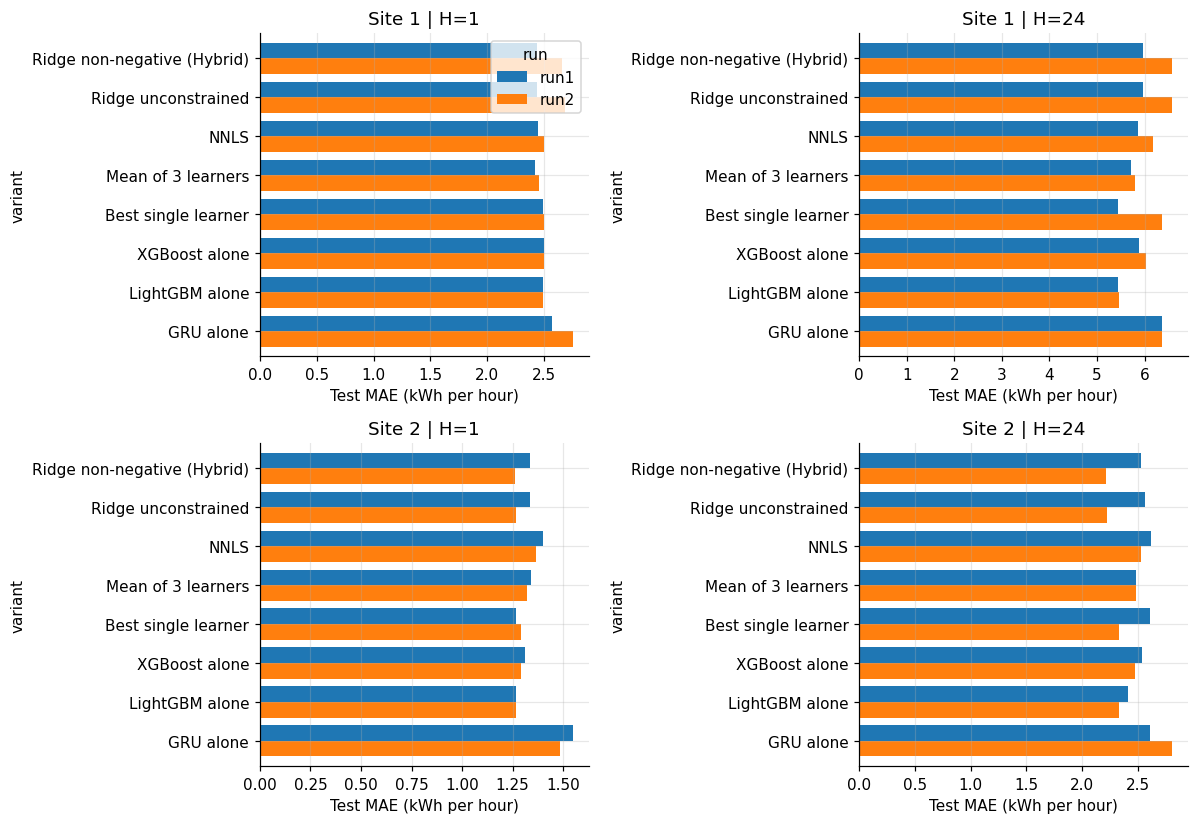

In [5]:
from sklearn.linear_model import Ridge
from scipy.optimize import nnls
ALPHAS = [1e-3, 1e-2, 0.1, 1, 10, 100, 1000]
def blocked_cv_alpha(P, y, positive, K=4):
    edges = np.linspace(0, len(y), K + 2).astype(int); best = None
    for a in ALPHAS:
        sc = []
        for j in range(1, K + 1):
            m = Ridge(alpha=a, positive=positive).fit(P[:edges[j]], y[:edges[j]])
            sc.append(np.mean(np.abs(np.clip(m.predict(P[edges[j]:edges[j+1]]), 0, None) - y[edges[j]:edges[j+1]])))
        if best is None or np.mean(sc) < best[1]: best = (a, float(np.mean(sc)))
    return best[0]
VARIANTS = ['Ridge non-negative (Hybrid)', 'Ridge unconstrained', 'NNLS', 'Mean of 3 learners', 'Best single learner']
FR, WROWS = [], []
for run, fit_split in [('run1', 'val'), ('run2', 'oof')]:
    for (site, h), G in BASE[BASE.run == run].groupby(['site', 'horizon']):
        F = G[G.split == fit_split].sort_values('time'); T = G[G.split == 'test'].sort_values('time')
        Pf, yf, Pt = F[LEARN].values, F.actual.values, T[LEARN].values
        out = {}
        a = blocked_cv_alpha(Pf, yf, True); m = Ridge(alpha=a, positive=True).fit(Pf, yf); out[VARIANTS[0]] = m.predict(Pt)
        WROWS.append(dict(run=run, site=site, horizon=h, variant=VARIANTS[0], alpha=a, intercept=m.intercept_, **dict(zip(LEARN, m.coef_))))
        a = blocked_cv_alpha(Pf, yf, False); m = Ridge(alpha=a).fit(Pf, yf); out[VARIANTS[1]] = m.predict(Pt)
        WROWS.append(dict(run=run, site=site, horizon=h, variant=VARIANTS[1], alpha=a, intercept=m.intercept_, **dict(zip(LEARN, m.coef_))))
        w, _ = nnls(Pf, yf); out[VARIANTS[2]] = Pt @ w
        WROWS.append(dict(run=run, site=site, horizon=h, variant=VARIANTS[2], alpha=np.nan, intercept=0.0, **dict(zip(LEARN, w))))
        out[VARIANTS[3]] = Pt.mean(axis=1)
        k = int(np.argmin(np.abs(Pf - yf[:, None]).mean(axis=0))); out[VARIANTS[4]] = Pt[:, k]
        WROWS.append(dict(run=run, site=site, horizon=h, variant=VARIANTS[4], alpha=np.nan, intercept=0.0, **{l: float(i == k) for i, l in enumerate(LEARN)}))
        for v, p in out.items():
            FR.append(pd.DataFrame({'time': T.time.values, 'site': site, 'horizon': h, 'run': run, 'split': 'test', 'actual': T.actual.values,
                                    'pred': np.clip(p, 0, None), 'variant': v}))
for l in LEARN:   # reference rows: each base learner alone
    for run in ['run1', 'run2']:
        T = BASE[(BASE.run == run) & (BASE.split == 'test')]
        FR.append(pd.DataFrame({'time': T.time.values, 'site': T.site.values, 'horizon': T.horizon.values, 'run': run, 'split': 'test',
                                'actual': T.actual.values, 'pred': np.clip(T[l].values, 0, None), 'variant': {'xgb': 'XGBoost alone', 'lgbm': 'LightGBM alone', 'gru': 'GRU alone'}[l]}))
ALLP = pd.concat(FR, ignore_index=True)
ROWS = []
for v, g in ALLP.groupby('variant'):
    r = evaluate_all(g.drop(columns='variant')); r = r[(r.group == 'Test') & r.metric.isin(['MAE', 'RMSE', 'R2', 'Peak_MAE'])]; r.insert(0, 'variant', v); ROWS.append(r)
RES_ALL = pd.concat(ROWS, ignore_index=True); RES_ALL.to_csv(os.path.join(OUT_DIR, f'{MODEL_TAG}_results_long.csv'), index=False)
CMP = RES_ALL.pivot_table(index=['run', 'site', 'horizon', 'variant'], columns='metric', values='value')[['MAE', 'RMSE', 'R2', 'Peak_MAE']]
CMP.to_csv(os.path.join(OUT_DIR, f'{MODEL_TAG}_comparison_test.csv')); print(CMP.round(4).to_string())
WT = pd.DataFrame(WROWS); WT.to_csv(os.path.join(OUT_DIR, f'{MODEL_TAG}_weights.csv'), index=False); print(WT.round(4).to_string())
BEST_V = CMP['MAE'].unstack('variant'); print('\nTest MAE by variant (rows run/site/horizon):\n', BEST_V.round(3).to_string())
json.dump({'variants': list(ALLP.variant.unique()), 'fit_split': {'run1': 'val', 'run2': 'oof (expanding, Train+Val)'}}, open(os.path.join(OUT_DIR, f'{MODEL_TAG}_best_hyperparameters.json'), 'w'), indent=2)
order = VARIANTS + ['XGBoost alone', 'LightGBM alone', 'GRU alone']
fig, axs = plt.subplots(len(SITES), len(HORIZONS), figsize=(5.5 * len(HORIZONS), 3.8 * len(SITES)), squeeze=False)
for i, site in enumerate(SITES):
    for j, h in enumerate(HORIZONS):
        d = BEST_V.xs((site, h), level=('site', 'horizon')).reindex(columns=order)
        d.T.plot.barh(ax=axs[i, j], width=.8, legend=(i == 0 and j == 0)); axs[i, j].set(title=f'Site {site} | H={h}', xlabel='Test MAE (kWh per hour)'); axs[i, j].invert_yaxis()
plt.tight_layout(); savefig('F1_meta_learner_comparison')